In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv(r"C:\Users\dell\OneDrive\Desktop\ML Projects\Food Delivery Time Prediction\datasets\Food_Delivery_Times.csv")
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [3]:
# Number of rows and column
df.shape

(1000, 9)

In [4]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [5]:
# Statistical summary
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,1000.000000,1000.000000,1000.000000,970.000000,1000.000000
mean,500.500000,10.059970,16.982000,4.579381,56.732000
std,288.819436,5.696656,7.204553,2.914394,22.070915
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,250.750000,5.105000,11.000000,2.000000,41.000000
50%,500.500000,10.190000,17.000000,5.000000,55.500000
75%,750.250000,15.017500,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,153.000000


In [6]:
# Columns name
df.columns

Index(['Order_ID', 'Distance_km', 'Weather', 'Traffic_Level', 'Time_of_Day',
       'Vehicle_Type', 'Preparation_Time_min', 'Courier_Experience_yrs',
       'Delivery_Time_min'],
      dtype='object')

In [7]:
# DataType
df.dtypes

Order_ID                    int64
Distance_km               float64
Weather                    object
Traffic_Level              object
Time_of_Day                object
Vehicle_Type               object
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

In [8]:
# Missing value
df.isnull().sum()          # 120

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64

In [9]:
# Duplicate record
df.duplicated().sum()               # 0

np.int64(0)

In [10]:
# Unique values in categorical columns
categorical_col = df.select_dtypes(include="object").columns

for col in categorical_col:
    print(f"\n{col}")
    print(df[col].unique())


Weather
['Windy' 'Clear' 'Foggy' 'Rainy' 'Snowy' nan]

Traffic_Level
['Low' 'Medium' 'High' nan]

Time_of_Day
['Afternoon' 'Evening' 'Night' 'Morning' nan]

Vehicle_Type
['Scooter' 'Bike' 'Car']


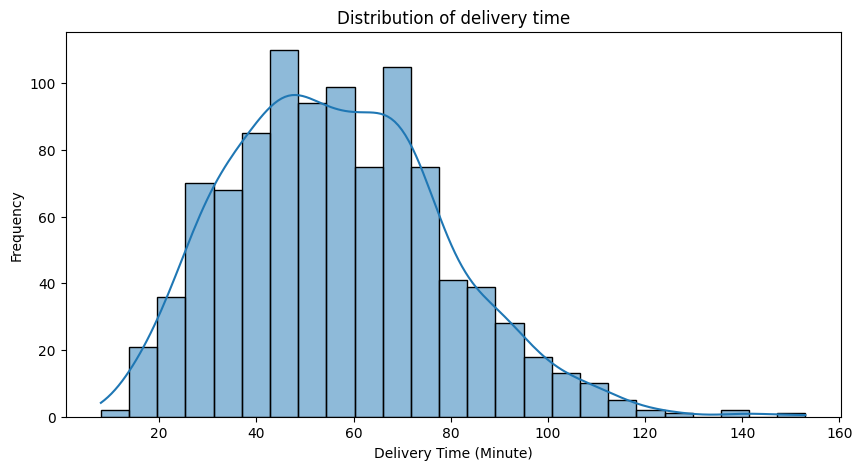

In [11]:
# Task 1: Distribution of delivery time
plt.figure(figsize=(10,5))

sns.histplot(df['Delivery_Time_min'],kde=True)

plt.title("Distribution of delivery time")
plt.xlabel("Delivery Time (Minute)")
plt.ylabel("Frequency")
plt.savefig("Distibution of delivery time.png",dpi=300)
plt.show()


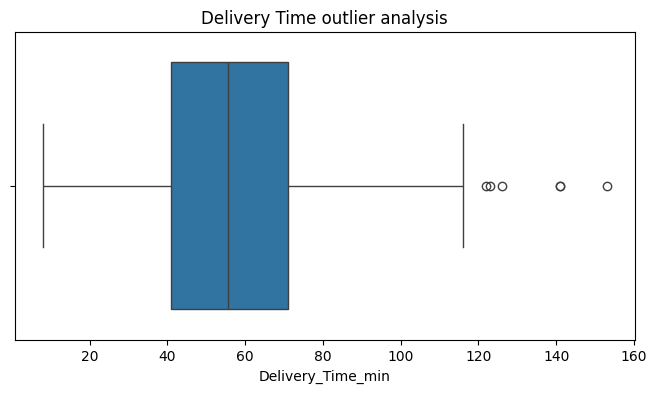

In [12]:
# Task 2: Boxplot – Delivery time
plt.figure(figsize=(8,4))
sns.boxplot(x=df['Delivery_Time_min'])
plt.title("Delivery Time outlier analysis")
plt.savefig("Delivery Time outlier analysis.png",dpi=300)
plt.show()


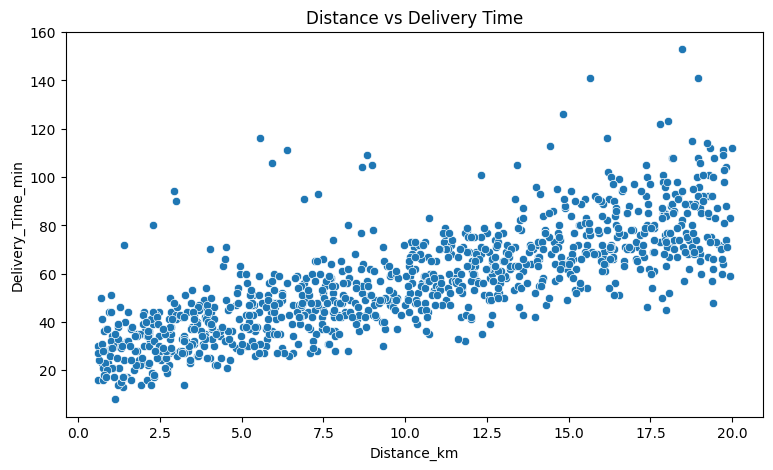

In [13]:
# Task 3: Distance vs Delivery Time

plt.figure(figsize=(9,5))

sns.scatterplot(data=df,x='Distance_km',y='Delivery_Time_min')
plt.title("Distance vs Delivery Time")
plt.savefig("Distance vs Delivery Time.png",dpi=300)
plt.show()


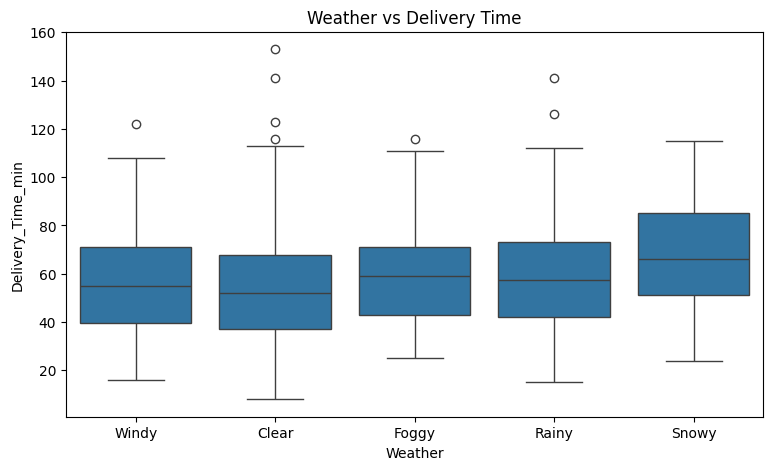

In [14]:
# Task 4: Weather vs Delivery Time
plt.figure(figsize=(9,5))

sns.boxplot(data=df,x='Weather',y='Delivery_Time_min')
plt.title("Weather vs Delivery Time")
plt.savefig("Weather vs Delivery Time.png",dpi=300)
plt.show()


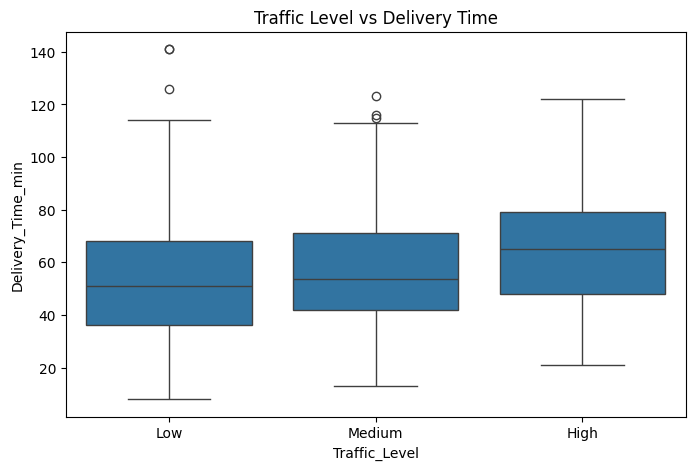

In [15]:
# Task 5: Traffic vs Delivery Time
plt.figure(figsize=(8,5))

sns.boxplot(data=df,x="Traffic_Level",y="Delivery_Time_min")
plt.title("Traffic Level vs Delivery Time")
plt.savefig("Traffic Level vs Delivery Time.png",dpi=300)
plt.show()


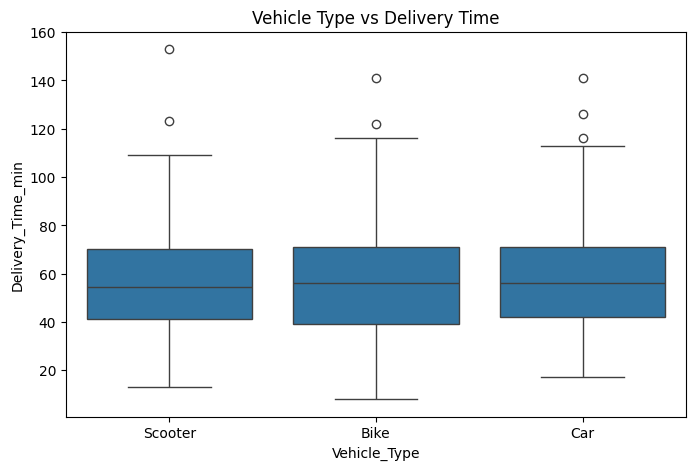

In [16]:
# Task 6: Vehicle Type vs Delivery Time
plt.figure(figsize=(8,5))

sns.boxplot(data=df,x="Vehicle_Type",y="Delivery_Time_min")
plt.title("Vehicle Type vs Delivery Time")
plt.savefig("Vehicle Type vs Delivery Time.png",dpi=300)
plt.show()


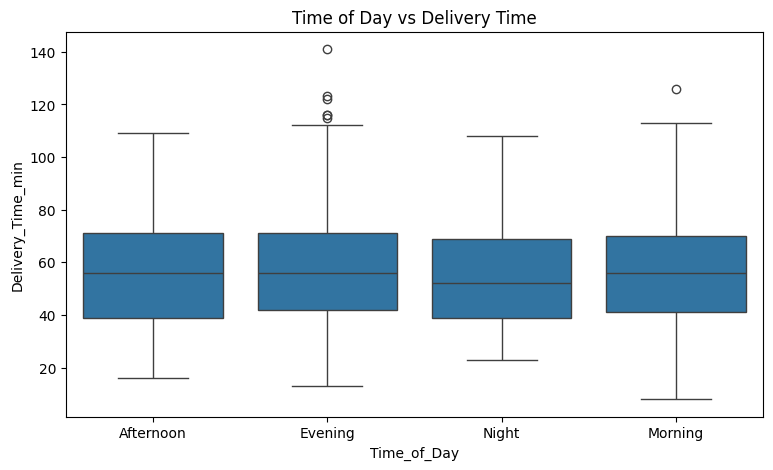

In [17]:
# Task 6 Time of Day vs Delivery Time
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='Time_of_Day',
    y='Delivery_Time_min'
)

plt.title('Time of Day vs Delivery Time')
plt.savefig("Time of Day vs Delivery Time.png",dpi=300)

plt.show()

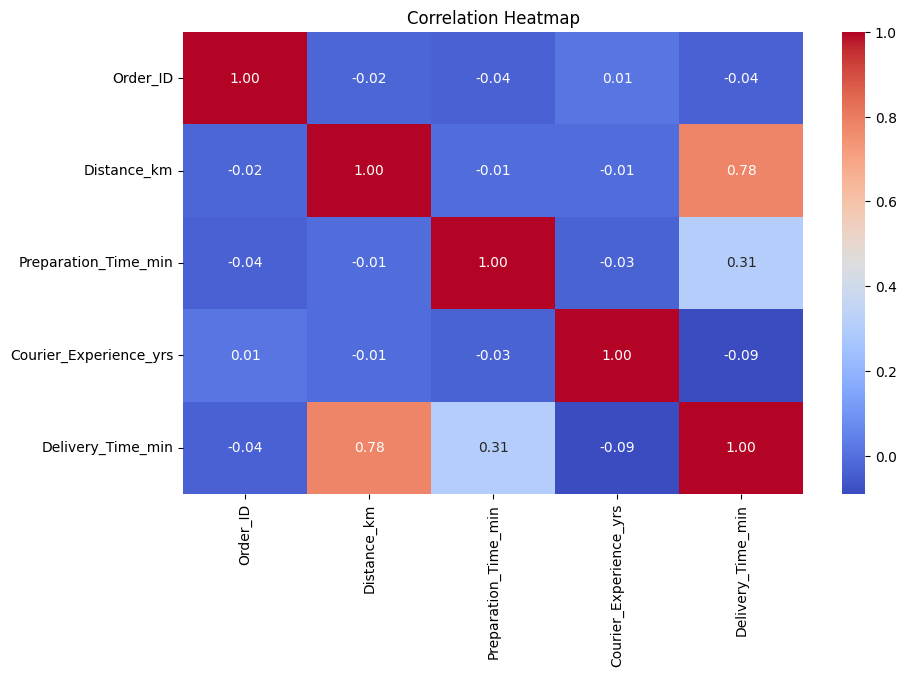

In [18]:
# Task 7 Correlation Heatmap
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.savefig("Correlation Heatmap.png",dpi=300)
plt.show()

### EDA summary for your project documentation

1. Delivery time has a positively skewed distribution.
2. Six potential outliers were identified using the IQR method.
3. Distance has the strongest positive correlation with delivery time (0.781).
4. Preparation time also positively correlates with delivery time (0.307).
5. High traffic is associated with higher median delivery time.
6. Snowy weather has the highest median delivery time among weather categories.
7. Vehicle types have relatively similar delivery-time distributions.
8. Courier experience has a weak negative correlation with delivery time.

### Phase 3 – Data Cleaning

In [19]:
# Create a copy of original dataset
df_clean = df.copy()

df_clean.shape

(1000, 9)

In [20]:
missing_report = pd.DataFrame({
    "Missing_Count":df_clean.isnull().sum(),
    "Missing_Percentage":(
        df_clean.isnull().sum()/len(df_clean))*100})

missing_report

,Missing_Count,Missing_Percentage
Order_ID,0,0.0
Distance_km,0,0.0
Weather,30,3.0
Traffic_Level,30,3.0
Time_of_Day,30,3.0
Vehicle_Type,0,0.0
Preparation_Time_min,0,0.0
Courier_Experience_yrs,30,3.0
Delivery_Time_min,0,0.0


In [21]:
# Total rows containing missing values
df_clean.isnull().any(axis=1).sum()

np.int64(117)

In [22]:
# Check duplicate rows
df_clean.duplicated().sum()

df_clean['Order_ID'].duplicated().sum()

np.int64(0)

In [23]:
# Check Invalid values
numerical_cols = df_clean.select_dtypes(include=np.number).columns

for col in numerical_cols:
    print(f"\n{col}")
    print("Minimum:", df_clean[col].min())
    print("Maximum:", df_clean[col].max())


Order_ID
Minimum: 1
Maximum: 1000

Distance_km
Minimum: 0.59
Maximum: 19.99

Preparation_Time_min
Minimum: 5
Maximum: 29

Courier_Experience_yrs
Minimum: 0.0
Maximum: 9.0

Delivery_Time_min
Minimum: 8
Maximum: 153


In [24]:
# Missing Values Treatment

# Categorical col
print("Weather mode:",df_clean['Weather'].mode()[0])
print("Traffic mode:",df_clean['Traffic_Level'].mode()[0])
print("Time of day mode:",df_clean['Time_of_Day'].mode()[0])

# Numerical col
print("Courier Experience Median:",df_clean["Courier_Experience_yrs"].median())

Weather mode: Clear
Traffic mode: Medium
Time of day mode: Morning
Courier Experience Median: 5.0


In [25]:
# Categorical missing values
df_clean['Weather'] = df_clean['Weather'].fillna(
    df_clean['Weather'].mode()[0]
)

df_clean['Traffic_Level'] = df_clean['Traffic_Level'].fillna(
    df_clean['Traffic_Level'].mode()[0]
)

df_clean['Time_of_Day'] = df_clean['Time_of_Day'].fillna(
    df_clean['Time_of_Day'].mode()[0]
)

# Numerical missing values
df_clean['Courier_Experience_yrs'] = df_clean[
    'Courier_Experience_yrs'
].fillna(df_clean['Courier_Experience_yrs'].median())

In [26]:
df_clean.isnull().sum()

Order_ID                  0
Distance_km               0
Weather                   0
Traffic_Level             0
Time_of_Day               0
Vehicle_Type              0
Preparation_Time_min      0
Courier_Experience_yrs    0
Delivery_Time_min         0
dtype: int64

In [27]:
# Check data types
df_clean.dtypes

Order_ID                    int64
Distance_km               float64
Weather                    object
Traffic_Level              object
Time_of_Day                object
Vehicle_Type               object
Preparation_Time_min        int64
Courier_Experience_yrs    float64
Delivery_Time_min           int64
dtype: object

In [28]:
# Check invalid numerical values
numerical_cols = [
    'Distance_km',
    'Preparation_Time_min',
    'Courier_Experience_yrs',
    'Delivery_Time_min'
]

for col in numerical_cols:
    print(f"\n{col}")
    print("Minimum:", df_clean[col].min())
    print("Maximum:", df_clean[col].max())
    print("Negative values:", (df_clean[col] < 0).sum())


Distance_km
Minimum: 0.59
Maximum: 19.99
Negative values: 0

Preparation_Time_min
Minimum: 5
Maximum: 29
Negative values: 0

Courier_Experience_yrs
Minimum: 0.0
Maximum: 9.0
Negative values: 0

Delivery_Time_min
Minimum: 8
Maximum: 153
Negative values: 0


In [29]:
# Outlier Detection
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Outliers:", len(outliers))


Column: Distance_km
Lower Bound: -9.763749999999998
Upper Bound: 29.886249999999997
Outliers: 0

Column: Preparation_Time_min
Lower Bound: -7.0
Upper Bound: 41.0
Outliers: 0

Column: Courier_Experience_yrs
Lower Bound: -5.5
Upper Bound: 14.5
Outliers: 0

Column: Delivery_Time_min
Lower Bound: -4.0
Upper Bound: 116.0
Outliers: 6


In [30]:
delivery_outliers = df_clean[
    df_clean['Delivery_Time_min'] > 116
]

delivery_outliers

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
29,948,18.05,Clear,Medium,Evening,Scooter,10,7.0,123
127,446,18.97,Clear,Low,Evening,Car,25,4.0,141
379,814,18.46,Clear,Medium,Morning,Scooter,29,1.0,153
452,394,15.64,Rainy,Low,Morning,Bike,20,4.0,141
784,385,14.83,Rainy,Low,Morning,Car,19,4.0,126
924,428,17.81,Windy,High,Evening,Bike,21,4.0,122


In [31]:
delivery_outliers[
    ['Distance_km',
     'Traffic_Level',
     'Weather',
     'Preparation_Time_min',
     'Courier_Experience_yrs',
     'Delivery_Time_min']
]

,Distance_km,Traffic_Level,Weather,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
29,18.05,Medium,Clear,10,7.0,123
127,18.97,Low,Clear,25,4.0,141
379,18.46,Medium,Clear,29,1.0,153
452,15.64,Low,Rainy,20,4.0,141
784,14.83,Low,Rainy,19,4.0,126
924,17.81,High,Windy,21,4.0,122


In [32]:
# Final dataset shape
print(df_clean.shape)

# Missing values
print(df_clean.isnull().sum().sum())

# Duplicate records
print(df_clean.duplicated().sum())

# Check target variable
print(df_clean['Delivery_Time_min'].describe())

(1000, 9)
0
0
count    1000.000000
mean       56.732000
std        22.070915
min         8.000000
25%        41.000000
50%        55.500000
75%        71.000000
max       153.000000
Name: Delivery_Time_min, dtype: float64


In [33]:
df_clean.to_csv(
    "Food_Delivery_Times_Cleaned.csv",
    index=False
)

### Phase 4 – Feature Engineering & Preprocessing

In [34]:
# Separate independent variable X
X = df.drop(columns=['Order_ID','Delivery_Time_min'])

# Separate dependent variable y
y = df['Delivery_Time_min']

In [35]:
# Check X and y shape
print("Features Shape:", X.shape)

print("Target Shape:", y.shape)

Features Shape: (1000, 7)
Target Shape: (1000,)


In [36]:
# # Display independent variables
X.head()

,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs
0,7.93,Windy,Low,Afternoon,Scooter,12,1.0
1,16.42,Clear,Medium,Evening,Bike,20,2.0
2,9.52,Foggy,Low,Night,Scooter,28,1.0
3,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0
4,19.03,Clear,Low,Morning,Bike,16,5.0


In [37]:
# Display target variable

y.head()

0    43
1    84
2    59
3    37
4    68
Name: Delivery_Time_min, dtype: int64

In [38]:
# Check feature columns
print("Numerical Features:-")
print(X.select_dtypes(include=np.number).columns.tolist())

print("\nCategorical Features:-")
print(X.select_dtypes(include="object").columns.tolist())

Numerical Features:-
['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']

Categorical Features:-
['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']


In [39]:
# Train-Test Split (80:20)
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42)

In [40]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (800, 7)
X_test: (200, 7)
y_train: (800,)
y_test: (200,)


In [41]:
# Identify numerical and categorical features
numerical_features = X_train.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object']).columns.tolist()

print("Numerical features:",numerical_features)
print("Categorical_features:",categorical_features)

Numerical features: ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']
Categorical_features: ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']


In [42]:
# Building Preprocessing Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [43]:
# Create Numerical Pipeline
numerical_pipeline = Pipeline(steps=[("imputer",SimpleImputer(strategy="median")),
                                     ("scaler",StandardScaler())])

categorical_pipeline = Pipeline(steps=[("imputer",SimpleImputer(strategy="most_frequent")),
                                       ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [44]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

In [45]:
# Fit and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

In [46]:
# Transform testing data
X_test_processed = preprocessor.transform(X_test)

In [47]:
# Check processed dataset
print("Training Data Shape:", X_train_processed.shape)

print("Testing Data Shape:", X_test_processed.shape)

Training Data Shape: (800, 18)
Testing Data Shape: (200, 18)


In [48]:
print("Missing Values in Training:",
      np.isnan(X_train_processed.toarray()).sum()
      if hasattr(X_train_processed, "toarray")
      else np.isnan(X_train_processed).sum())

Missing Values in Training: 0


In [49]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)
print("Total Features:", len(feature_names))

['num__Distance_km' 'num__Preparation_Time_min'
 'num__Courier_Experience_yrs' 'cat__Weather_Clear' 'cat__Weather_Foggy'
 'cat__Weather_Rainy' 'cat__Weather_Snowy' 'cat__Weather_Windy'
 'cat__Traffic_Level_High' 'cat__Traffic_Level_Low'
 'cat__Traffic_Level_Medium' 'cat__Time_of_Day_Afternoon'
 'cat__Time_of_Day_Evening' 'cat__Time_of_Day_Morning'
 'cat__Time_of_Day_Night' 'cat__Vehicle_Type_Bike' 'cat__Vehicle_Type_Car'
 'cat__Vehicle_Type_Scooter']
Total Features: 18


In [50]:
# Check training and testing shapes
print("Original X_train:", X_train.shape)
print("Processed X_train:", X_train_processed.shape)

print("Original X_test:", X_test.shape)
print("Processed X_test:", X_test_processed.shape)

Original X_train: (800, 7)
Processed X_train: (800, 18)
Original X_test: (200, 7)
Processed X_test: (200, 18)


In [51]:
# Check missing values
from scipy import sparse

if sparse.issparse(X_train_processed):
    train_missing = np.isnan(X_train_processed.data).sum()
else:
    train_missing = np.isnan(X_train_processed).sum()

print("Training missing values:", train_missing)

if sparse.issparse(X_test_processed):
    test_missing = np.isnan(X_test_processed.data).sum()
else:
    test_missing = np.isnan(X_test_processed).sum()

print("Testing missing values:", test_missing)

Training missing values: 0
Testing missing values: 0


In [52]:
# Check target variables
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Target: (800,)
Testing Target: (200,)


### Phase 5 – Machine Learning Model Building

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import GradientBoostingRegressor

In [54]:
# Create ML models
models = {
    "Linear Regression":LinearRegression(),
    "Decision Tree":DecisionTreeRegressor(random_state=42),
    "Random Forest":RandomForestRegressor(n_estimators=100,random_state=42),
    "KNN":KNeighborsRegressor(n_neighbors=5),
"Gradient Boosting":GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,random_state=42)}


In [55]:
# Train all five models
trained_models = {}

for name,model in models.items():
    model.fit(X_train_processed,y_train)
    trained_models[name]=model
    print(f"{name} trained successfully")

Linear Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
KNN trained successfully
Gradient Boosting trained successfully


In [56]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_processed)

    predictions[name] = y_pred

    print(f"{name} predictions generated!")

Linear Regression predictions generated!
Decision Tree predictions generated!
Random Forest predictions generated!
KNN predictions generated!
Gradient Boosting predictions generated!


In [57]:
prediction_comparison = pd.DataFrame({
    'Actual_Delivery_Time': y_test.values,

    'Linear_Regression': predictions['Linear Regression'],

    'Decision_Tree': predictions['Decision Tree'],

    'Random_Forest': predictions['Random Forest'],

    'KNN': predictions['KNN'],

    'Gradient_Boosting': predictions['Gradient Boosting']
})

prediction_comparison.head(10)

,Actual_Delivery_Time,Linear_Regression,Decision_Tree,Random_Forest,KNN,Gradient_Boosting
0,32,35.650999,31.0,34.58,45.8,35.792224
1,68,61.268365,60.0,65.20,69.0,62.344783
2,39,44.543129,30.0,40.40,58.0,45.116413
3,44,43.800204,51.0,45.78,51.8,46.416007
4,85,80.639241,92.0,80.51,75.6,79.479354
5,31,32.600398,26.0,33.97,38.8,33.244442
6,77,69.208358,70.0,66.84,70.2,70.894800
7,33,32.364291,25.0,35.10,43.2,33.310950
8,90,37.294282,27.0,33.17,47.0,41.242672
9,91,77.909966,86.0,78.10,73.6,79.339086


### Phase 6 – Model Evaluation

In [58]:
from sklearn.metrics import (
mean_absolute_error,mean_squared_error,r2_score)

In [61]:
# Evaluate all five models
evaluation_results = []

for name,y_pred in predictions.items():
    mae = mean_absolute_error(y_test,y_pred)
    mse = mean_squared_error(y_test,y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test,y_pred)

    evaluation_results.append({
    'Model':name,
    'MAE':mae,
    'MSE': mse,
    'RMSE': rmse,
    'R2_Score': r2
    })

In [62]:
# Create Model Comparison Table
results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

results_df

,Model,MAE,MSE,RMSE,R2_Score
0,Linear Regression,6.063415,80.141359,8.952171,0.821204
4,Gradient Boosting,6.520151,85.963692,9.271661,0.808214
2,Random Forest,6.883050,92.516179,9.618533,0.793595
3,KNN,8.650000,132.147600,11.495547,0.705177
1,Decision Tree,11.290000,249.910000,15.808542,0.442448


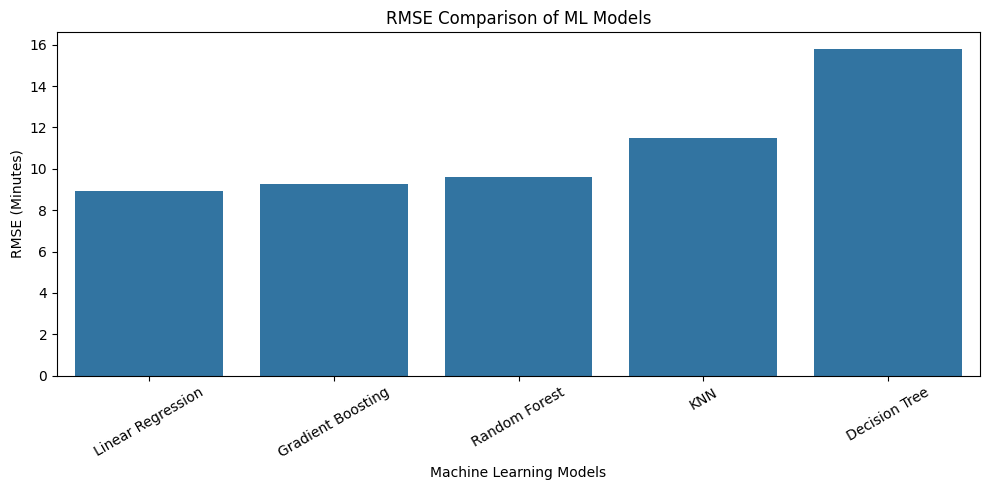

In [65]:
# Visualize Model Performance
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='RMSE'
)

plt.title('RMSE Comparison of ML Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('RMSE (Minutes)')

plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('RMSE Comparison of ML Models.png',dpi=300)
plt.show()

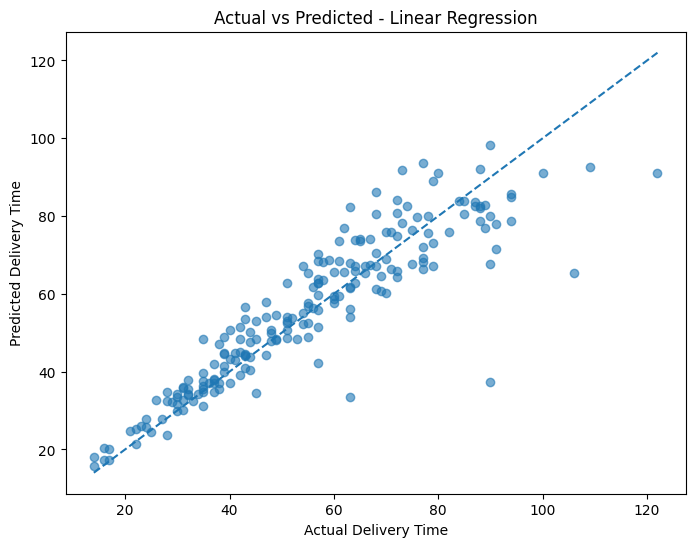

In [64]:
# Actual vs Predicted Visualization
best_model_name = results_df.iloc[0]['Model']

best_predictions = predictions[best_model_name]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel('Actual Delivery Time')
plt.ylabel('Predicted Delivery Time')

plt.title(f'Actual vs Predicted - {best_model_name}')

plt.show()

### Phase 7 – Model Saving Using Joblib

In [66]:

# Select best model
best_model_name = results_df.loc[
    results_df['RMSE'].idxmin(), 'Model'
]

print("Best Model:", best_model_name)

Best Model: Linear Regression


In [67]:
best_model = trained_models[best_model_name]

print(best_model)

LinearRegression()


In [70]:
# Create Complete ML Pipeline
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline(steps=[('preprocessor',preprocessor),
                                 ("model",best_model)])

final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Distance_km','Weather','Traffic_Level',...,'Vehicle_Type', 'Preparation_Time_min','Courier_Experience_yrs']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [71]:
# Test Final Pipeline
final_predictions = final_pipeline.predict(X_test)

print("First 10 Predictions:")
print(final_predictions[:10])

First 10 Predictions:
[35.65099934 61.26836506 44.54312934 43.800204   80.63924127 32.60039768
 69.20835777 32.36429138 37.29428197 77.9099664 ]


In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_mae = mean_absolute_error(y_test, final_predictions)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_r2 = r2_score(y_test, final_predictions)

print("Final Model:", best_model_name)
print("MAE:", final_mae)
print("RMSE:", final_rmse)
print("R2 Score:", final_r2)

Final Model: Linear Regression
MAE: 6.063414905264768
RMSE: 8.952170614738876
R2 Score: 0.8212036240893484


In [74]:
# Save Model Using Joblib
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    final_pipeline,
    "models/food_delivery_prediction_model.pkl"
)

['models/food_delivery_prediction_model.pkl']

In [75]:
# Load Saved Model
loaded_model = joblib.load(
    "models/food_delivery_prediction_model.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


In [76]:
# Test Prediction Using Loaded Model
sample_input = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_input)

print("Input Data:")
display(sample_input)

print("Predicted Delivery Time:", prediction[0], "Minutes")
print("Actual Delivery Time:", y_test.iloc[0], "Minutes")

Input Data:


,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs
521,5.3,Clear,Low,Evening,Bike,16,5.0


Predicted Delivery Time: 35.650999340197565 Minutes
Actual Delivery Time: 32 Minutes
